# PSO-trained MLP: Hyperparameter Experiments
Banknote authentication (binary classification, 4 features). All library code (`mlp/`, `pso/`, `adapter.py`) is pure NumPy and lives in `.py` files; this notebook only **runs experiments and shows results**

**Protocol (why the numbers are trustworthy)**
- 20% **test** set: used only in the final section.
- Remaining 80% is split into **fit** (60% of total) and **validation** (20% of total). All sweeps train on *fit* and are compared on *validation*, so no tuning decision looks at the test set.
- Every setting is repeated over several PSO seeds (PSO is stochastic); tables show mean $\pm$ std.
- z-scoring is fitted only on the data PSO trains on.

**Spec note:** the velocity update has four terms (inertia $\alpha$, cognitive $\beta$, informants $\delta$, global-best $\gamma$). The spec's example only passes three coefficients, so $\gamma$ defaults to **0** here and is swept separately.

In [1]:
import os, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from experiments import (DEFAULT_CONFIG, make_data, make_configs, run_experiment, summarise,
                         histories_by_label, to_frame, paired_permutation_test,
                         plot_convergence, plot_metric_vs_param)

N_SEEDS = int(os.environ.get("N_SEEDS", 10))   # set N_SEEDS=3 for a quick dry run
SEEDS = range(N_SEEDS)
data = make_data()
os.makedirs("results", exist_ok=True)
print({k: (v[0].shape, int(v[1].sum())) for k, v in data.items()}, "| seeds:", N_SEEDS)
print("Default config:", DEFAULT_CONFIG)
pd.set_option("display.float_format", "{:.4f}".format)

{'fit': ((824, 4), 366), 'val': ((274, 4), 122), 'train': ((1098, 4), 488), 'test': ((274, 4), 122)} | seeds: 10
Default config: {'hidden': [8], 'activations': ['tanh'], 'strategy': 'nearest', 'k': 3, 'particles': 30, 'iterations': 100, 'alpha': 0.7, 'beta': 1.5, 'delta': 1.5, 'gamma': 0.0, 'epsilon': 1.0}


## 1. Baseline run and Convergence

label,default
train_loss_mean,0.0111
train_loss_std,0.0056
eval_loss_mean,0.0158
eval_loss_std,0.0138
eval_accuracy_mean,0.9974
eval_accuracy_std,0.0046
eval_f1_mean,0.9972
eval_f1_std,0.0051
iters_to_within_5pct_mean,88.6000
iters_to_within_5pct_std,9.7775


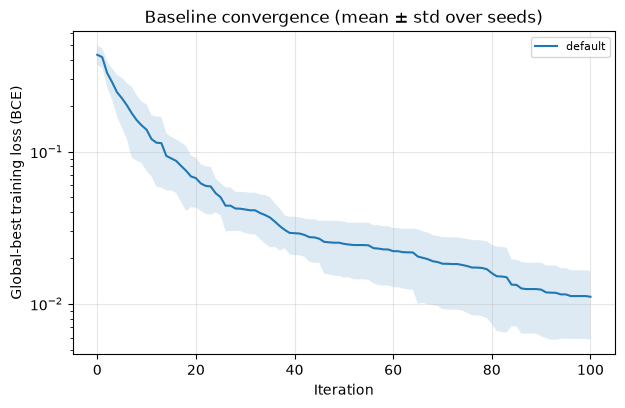

In [2]:
base = run_experiment({"default": DEFAULT_CONFIG}, SEEDS, data, mode="val")
display(summarise(base).T)
plot_convergence(histories_by_label(base), "Baseline convergence (mean ± std over seeds)")
plt.show()

## 2. Sweeps (one hyperparameter at a time, others at default)
Each cell runs the sweep, prints a summary table and a box-plot. Results are collected in `RESULTS` and written to `results/`.

*Caveat for the analysis:* `particles` or `iterations` changes the total evaluation budget (particles x (iterations+1)), so improvements there are partly "more compute". The `evaluations` column lets you check that.

In [3]:
RESULTS = {}

def sweep(name, param, values, xlabel=None, metric="eval_accuracy"):
    res = run_experiment(make_configs(param, values), SEEDS, data, mode="val")
    RESULTS[name] = res
    s = summarise(res)
    s["evaluations"] = to_frame(res).groupby("label", sort=False)["evaluations"].first()
    display(s[["train_loss_mean", "train_loss_std", "eval_loss_mean", "eval_accuracy_mean",
               "eval_accuracy_std", "eval_f1_mean", "iters_to_within_5pct_mean",
               "evaluations", "seconds_mean"]])
    fig, axs = plt.subplots(1, 3, figsize=(16, 4))
    plot_metric_vs_param(res, "train_loss", xlabel or param, "Training loss", axs[0]); axs[0].set_yscale("log")
    plot_metric_vs_param(res, "eval_accuracy", xlabel or param, "Validation accuracy", axs[1])
    plot_convergence(histories_by_label(res), "Convergence", ax=axs[2])
    plt.tight_layout(); plt.show()

### 2.1 MLP Hyperparameters

,train_loss_mean,train_loss_std,eval_loss_mean,eval_accuracy_mean,eval_accuracy_std,eval_f1_mean,iters_to_within_5pct_mean,evaluations,seconds_mean
label,,,,,,,,,
[2],0.0116,0.0044,0.0087,0.9993,0.0015,0.9992,93.2000,3030,0.4494
[4],0.0084,0.0044,0.0085,0.9985,0.0031,0.9984,91.6000,3030,0.4816
[8],0.0111,0.0056,0.0158,0.9974,0.0046,0.9972,88.6000,3030,0.5328
[16],0.0189,0.0144,0.0260,0.9934,0.0107,0.9928,88.1000,3030,0.5614
[32],0.0272,0.0261,0.0268,0.9901,0.0057,0.9891,79.2000,3030,0.7025


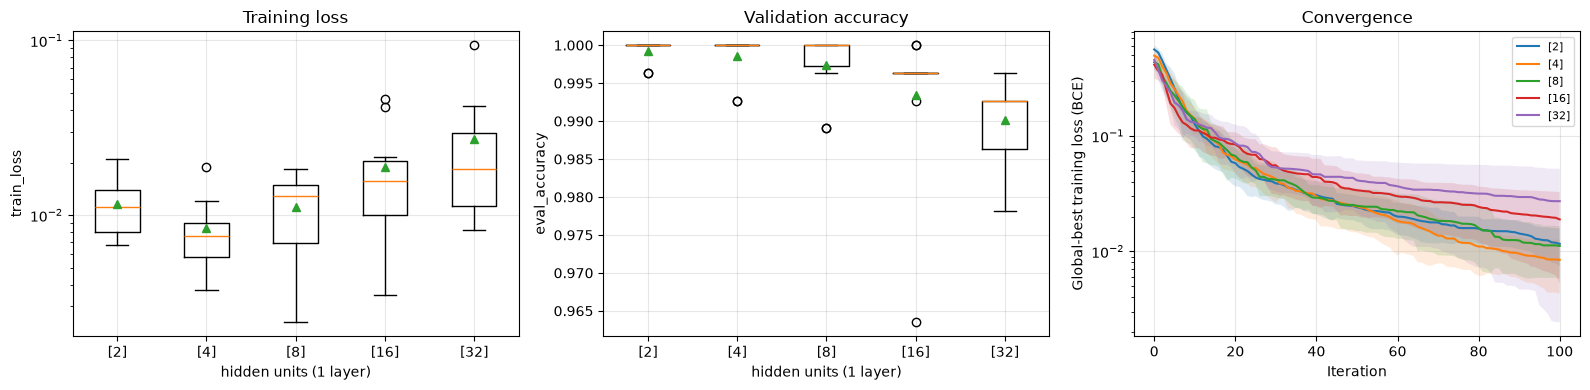

In [4]:
sweep("mlp_width", "hidden", [[2], [4], [8], [16], [32]], "hidden units (1 layer)")

,train_loss_mean,train_loss_std,eval_loss_mean,eval_accuracy_mean,eval_accuracy_std,eval_f1_mean,iters_to_within_5pct_mean,evaluations,seconds_mean
label,,,,,,,,,
[8],0.0111,0.0056,0.0158,0.9974,0.0046,0.9972,88.6000,3030,0.5429
"[8, 8]",0.0268,0.0259,0.0317,0.9872,0.0189,0.9862,72.8000,3030,0.6447
"[8, 8, 8]",0.0728,0.0417,0.1110,0.9682,0.0141,0.9655,68.2000,3030,0.8040


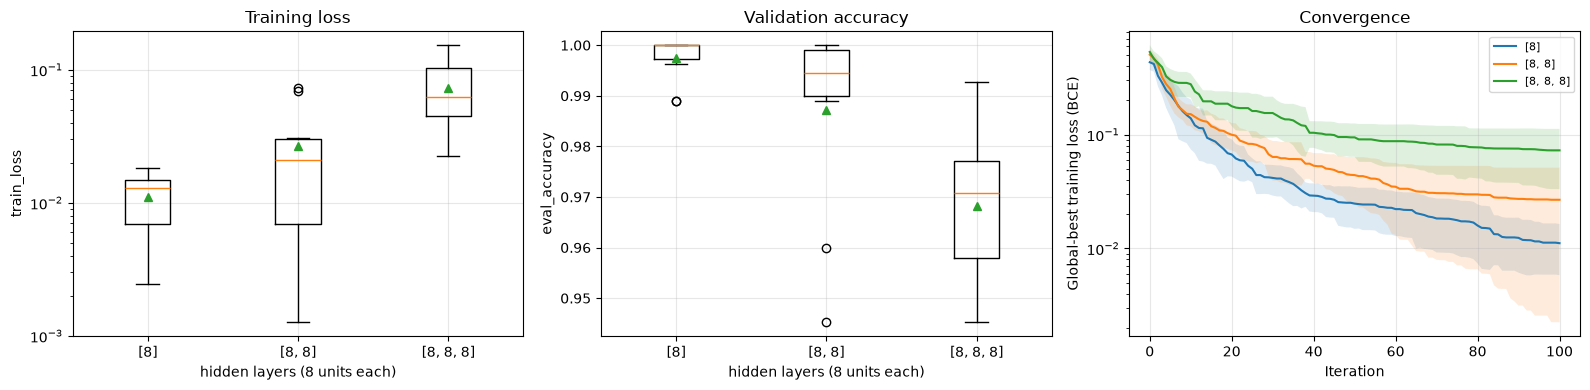

In [5]:
sweep("mlp_depth", "hidden", [[8], [8, 8], [8, 8, 8]], "hidden layers (8 units each)")

,train_loss_mean,train_loss_std,eval_loss_mean,eval_accuracy_mean,eval_accuracy_std,eval_f1_mean,iters_to_within_5pct_mean,evaluations,seconds_mean
label,,,,,,,,,
['tanh'],0.0111,0.0056,0.0158,0.9974,0.0046,0.9972,88.6000,3030,0.3772
['sigmoid'],0.0165,0.0083,0.0189,0.9956,0.0068,0.9952,87.5000,3030,0.7812


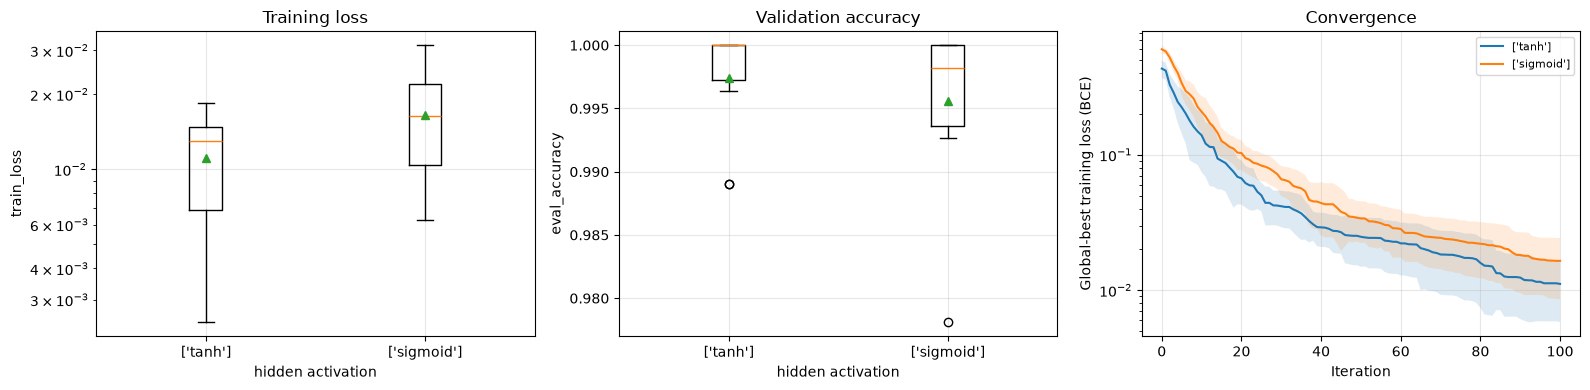

In [6]:
sweep("mlp_activation", "activations", [["tanh"], ["sigmoid"]], "hidden activation")

### 2.2 PSO Hyperparameters

,train_loss_mean,train_loss_std,eval_loss_mean,eval_accuracy_mean,eval_accuracy_std,eval_f1_mean,iters_to_within_5pct_mean,evaluations,seconds_mean
label,,,,,,,,,
10,0.0194,0.0150,0.0292,0.9869,0.0152,0.9857,86.6000,1010,0.1669
20,0.0107,0.0064,0.0139,0.9974,0.0030,0.9971,85.2000,2020,0.3361
30,0.0111,0.0056,0.0158,0.9974,0.0046,0.9972,88.6000,3030,0.5115
50,0.0052,0.0053,0.0055,1.0000,0.0000,1.0000,91.7000,5050,0.7892
100,0.0029,0.0014,0.0041,0.9996,0.0012,0.9996,94.4000,10100,1.5345


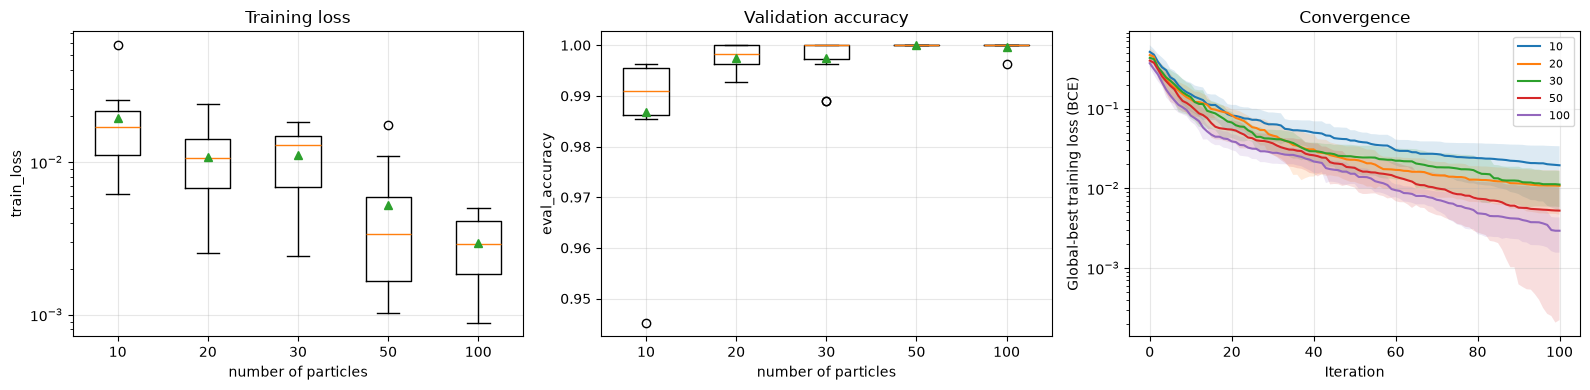

In [7]:
sweep("pso_particles", "particles", [10, 20, 30, 50, 100], "number of particles")

,train_loss_mean,train_loss_std,eval_loss_mean,eval_accuracy_mean,eval_accuracy_std,eval_f1_mean,iters_to_within_5pct_mean,evaluations,seconds_mean
label,,,,,,,,,
25,0.0502,0.0126,0.0598,0.9788,0.0077,0.9768,20.8000,780,0.1436
50,0.0248,0.0105,0.0309,0.9883,0.0099,0.9871,41.1000,1530,0.3055
100,0.0111,0.0056,0.0158,0.9974,0.0046,0.9972,88.6000,3030,0.6131
200,0.0039,0.0044,0.0057,0.9989,0.0025,0.9988,192.6000,6030,1.0219
400,0.0011,0.0023,0.0017,1.0000,0.0000,1.0000,377.8000,12030,1.6537


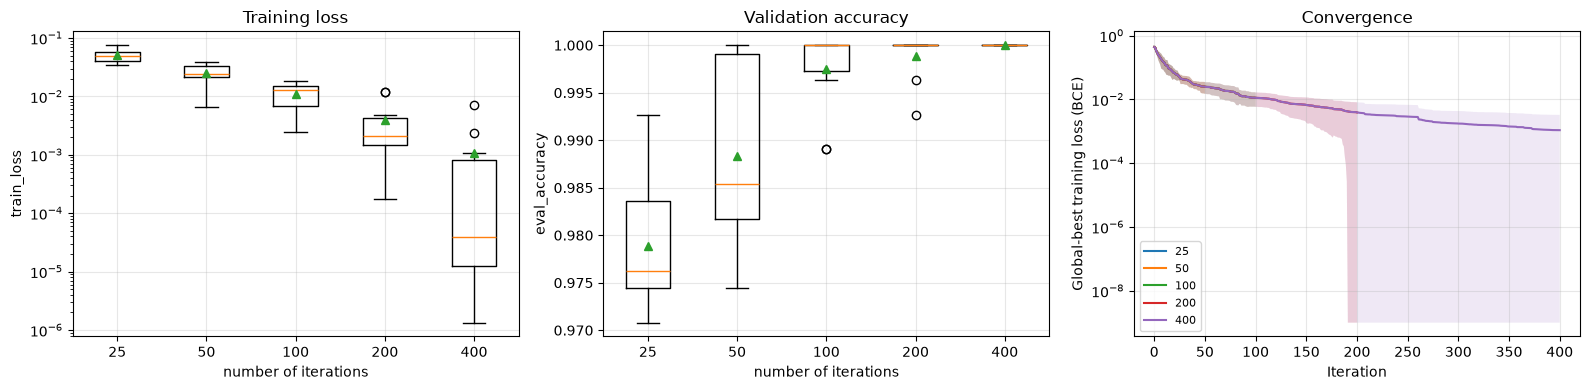

In [8]:
sweep("pso_iterations", "iterations", [25, 50, 100, 200, 400], "number of iterations")

,train_loss_mean,train_loss_std,eval_loss_mean,eval_accuracy_mean,eval_accuracy_std,eval_f1_mean,iters_to_within_5pct_mean,evaluations,seconds_mean
label,,,,,,,,,
0.3,0.0810,0.0354,0.0962,0.9635,0.0154,0.9607,29.5000,3030,0.4711
0.5,0.0134,0.0061,0.0155,0.9978,0.0035,0.9976,79.8000,3030,0.4820
0.7,0.0111,0.0056,0.0158,0.9974,0.0046,0.9972,88.6000,3030,0.4898
0.9,0.1073,0.0399,0.1448,0.9551,0.0212,0.9502,13.4000,3030,0.4229
1.0,0.1376,0.0514,0.1484,0.9504,0.0254,0.9448,9.0000,3030,0.3470


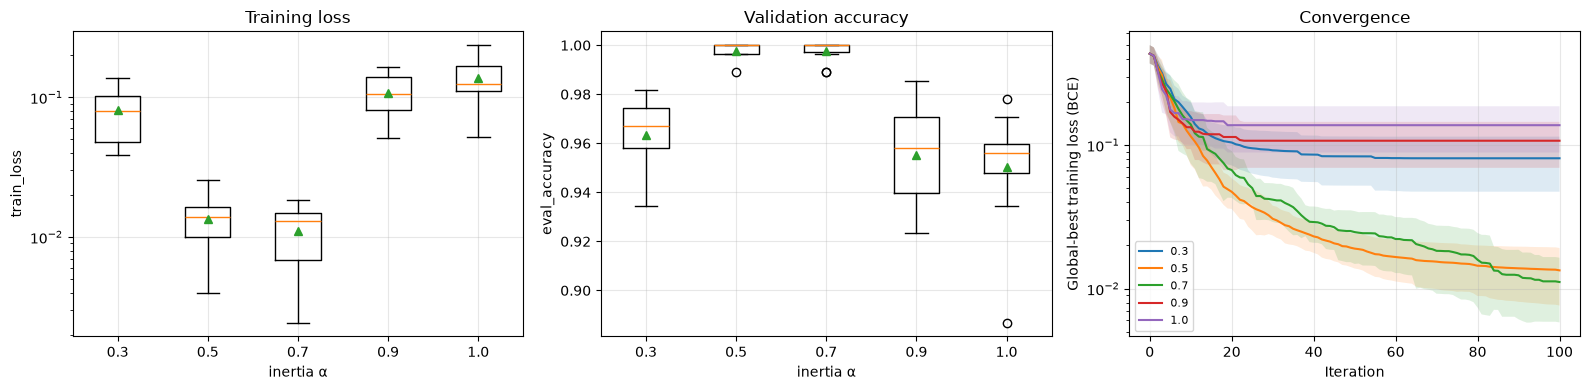

In [9]:
sweep("pso_alpha", "alpha", [0.3, 0.5, 0.7, 0.9, 1.0], "inertia α")

,train_loss_mean,train_loss_std,eval_loss_mean,eval_accuracy_mean,eval_accuracy_std,eval_f1_mean,iters_to_within_5pct_mean,evaluations,seconds_mean
label,,,,,,,,,
0.0,0.0463,0.0403,0.0717,0.9810,0.0150,0.9792,50.4000,3030,0.5619
0.5,0.0064,0.0074,0.0065,0.9993,0.0015,0.9992,90.3000,3030,0.5619
1.0,0.0035,0.0024,0.0048,0.9996,0.0012,0.9996,95.1000,3030,0.5628
1.5,0.0111,0.0056,0.0158,0.9974,0.0046,0.9972,88.6000,3030,0.4873
2.0,0.0345,0.0147,0.0433,0.9839,0.0116,0.9824,51.9000,3030,0.4082
2.5,0.1179,0.0584,0.1481,0.9438,0.0317,0.9362,13.4000,3030,0.4015


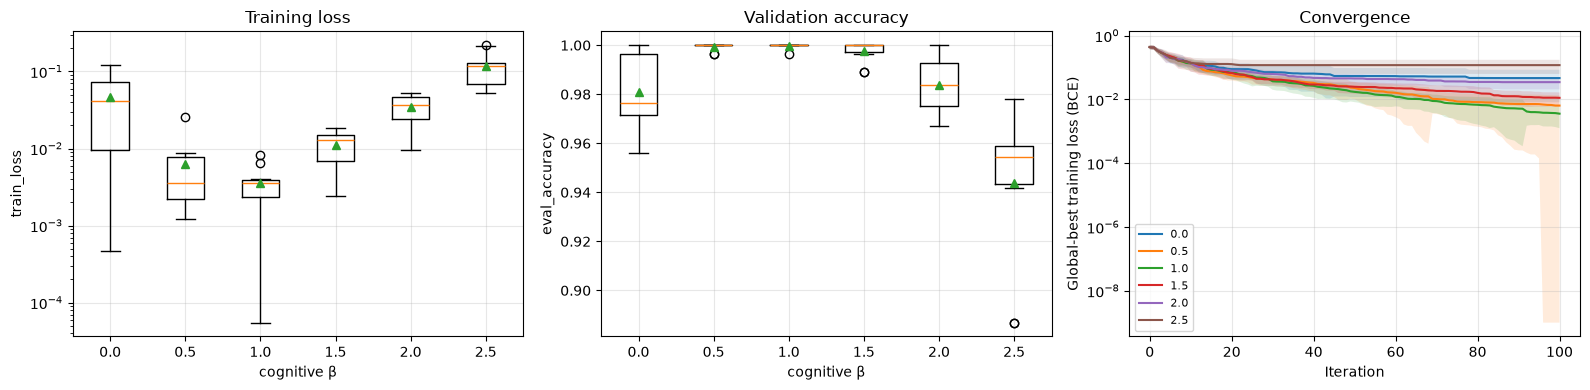

In [10]:
sweep("pso_beta", "beta", [0.0, 0.5, 1.0, 1.5, 2.0, 2.5], "cognitive β")

,train_loss_mean,train_loss_std,eval_loss_mean,eval_accuracy_mean,eval_accuracy_std,eval_f1_mean,iters_to_within_5pct_mean,evaluations,seconds_mean
label,,,,,,,,,
0.0,0.4128,0.0591,0.4224,0.8325,0.0617,0.8019,1.3000,3030,0.5162
0.5,0.1042,0.0250,0.1156,0.9631,0.0056,0.9598,48.0000,3030,0.5300
1.0,0.0163,0.0074,0.0181,0.9978,0.0035,0.9976,83.5000,3030,0.5159
1.5,0.0111,0.0056,0.0158,0.9974,0.0046,0.9972,88.6000,3030,0.4916
2.0,0.0928,0.0536,0.1036,0.9617,0.0231,0.9573,28.0000,3030,0.4554
2.5,0.1962,0.0670,0.2351,0.9190,0.0493,0.9091,6.4000,3030,0.4484


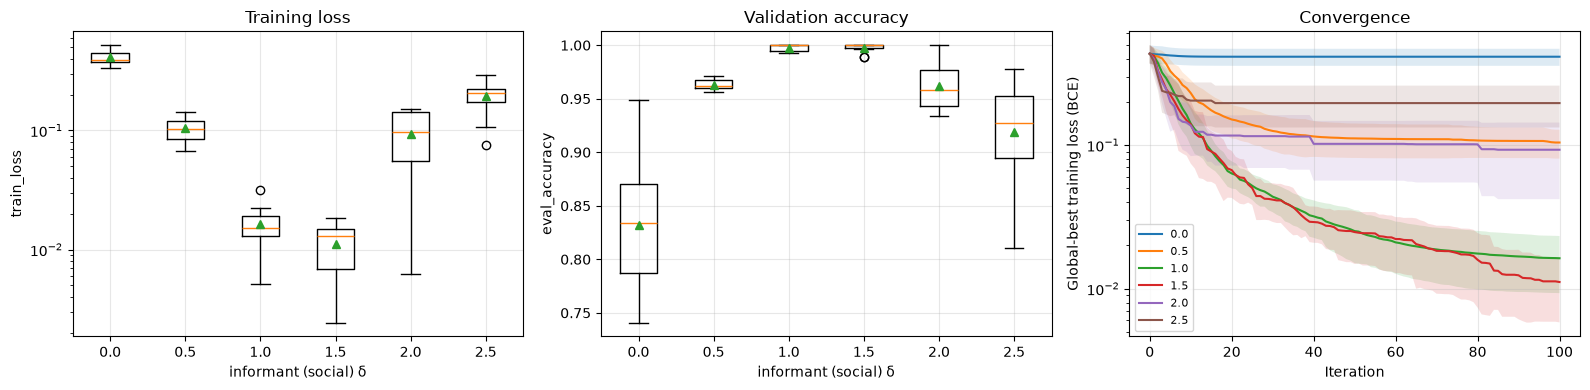

In [11]:
sweep("pso_delta", "delta", [0.0, 0.5, 1.0, 1.5, 2.0, 2.5], "informant (social) δ")

,train_loss_mean,train_loss_std,eval_loss_mean,eval_accuracy_mean,eval_accuracy_std,eval_f1_mean,iters_to_within_5pct_mean,evaluations,seconds_mean
label,,,,,,,,,
0.0,0.0111,0.0056,0.0158,0.9974,0.0046,0.9972,88.6000,3030,0.5479
0.5,0.0480,0.0356,0.0523,0.9818,0.0122,0.9798,41.5000,3030,0.5617
1.0,0.0419,0.0184,0.0473,0.9832,0.0091,0.9814,51.0000,3030,0.5606
1.5,0.0641,0.0349,0.0968,0.9701,0.0184,0.9673,28.9000,3030,0.4682


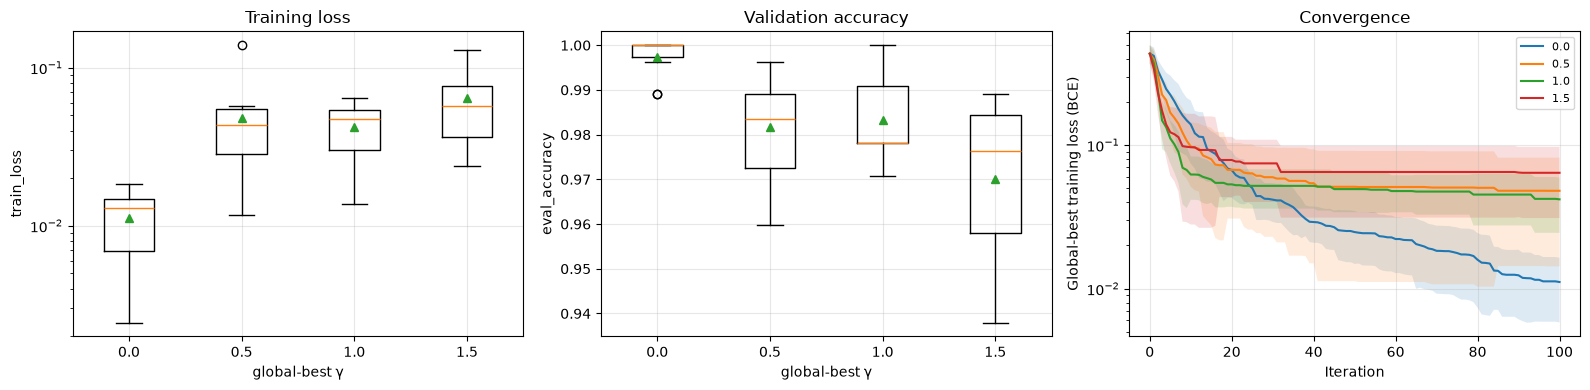

In [12]:
sweep("pso_gamma", "gamma", [0.0, 0.5, 1.0, 1.5], "global-best γ")

,train_loss_mean,train_loss_std,eval_loss_mean,eval_accuracy_mean,eval_accuracy_std,eval_f1_mean,iters_to_within_5pct_mean,evaluations,seconds_mean
label,,,,,,,,,
0.25,0.1886,0.0726,0.1991,0.9401,0.0279,0.9344,30.2000,3030,0.5717
0.5,0.0471,0.0120,0.0566,0.9876,0.0109,0.9864,55.3000,3030,0.5740
0.75,0.0148,0.0069,0.0196,0.9956,0.0066,0.9952,87.1000,3030,0.5709
1.0,0.0111,0.0056,0.0158,0.9974,0.0046,0.9972,88.6000,3030,0.5144
1.25,0.1028,0.0584,0.1262,0.9569,0.0300,0.9522,21.8000,3030,0.4000


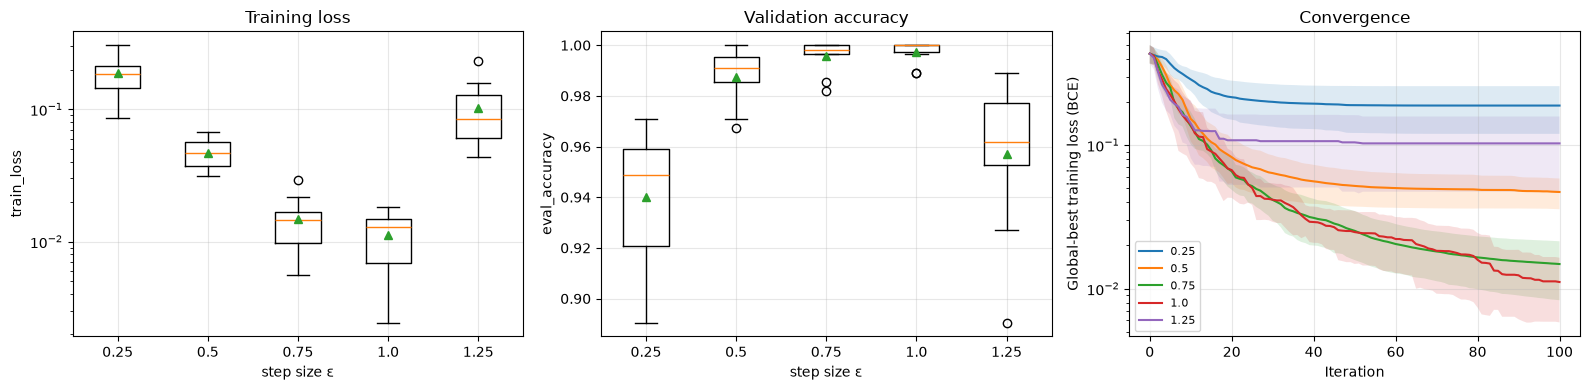

In [13]:
sweep("pso_epsilon", "epsilon", [0.25, 0.5, 0.75, 1.0, 1.25], "step size ε")

## 3. Informant Selection: Random vs Nearest Neighbour
Both strategies across several informant counts *k* (1 $\le$ k $\le$ N-1 = 29). Because each seed fixes the initial particles, runs are **paired** across strategies, which the permutation test below exploits.

,train_loss_mean,train_loss_std,eval_accuracy_mean,eval_f1_mean,iters_to_within_5pct_mean
label,,,,,
random-k1,0.0957,0.0383,0.9602,0.9566,43.5000
random-k2,0.1076,0.0249,0.9613,0.9573,32.9000
random-k3,0.0956,0.0350,0.9602,0.9567,25.4000
random-k5,0.0900,0.0263,0.9650,0.9612,19.8000
random-k10,0.0504,0.0199,0.9818,0.9797,53.4000
random-k20,0.0035,0.0037,0.9989,0.9988,86.5000
random-k29,0.0003,0.0004,0.9996,0.9996,97.8000
nearest-k1,0.0251,0.0106,0.9920,0.9911,87.5000
nearest-k2,0.0111,0.0051,0.9974,0.9971,86.9000


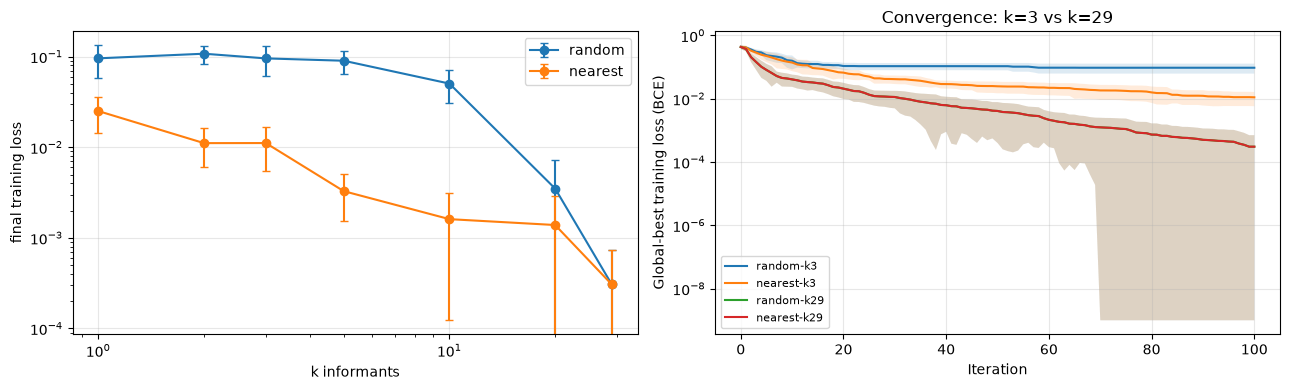

,mean(random - nearest) train loss,p (sign-flip)
k,,
1,0.0706,0.0021
2,0.0965,0.0021
3,0.0844,0.0021
5,0.0868,0.0021
10,0.0488,0.0021
20,0.0021,0.0873
29,0.0000,1.0000


In [14]:
KS = [1, 2, 3, 5, 10, 20, 29]
configs = {}
for strat in ("random", "nearest"):
    for k in KS:
        c = dict(DEFAULT_CONFIG); c["strategy"] = strat; c["k"] = k
        configs[f"{strat}-k{k}"] = c
inf = run_experiment(configs, SEEDS, data, mode="val")
RESULTS["informants"] = inf
s = summarise(inf)
display(s[["train_loss_mean", "train_loss_std", "eval_accuracy_mean", "eval_f1_mean", "iters_to_within_5pct_mean"]])

df = to_frame(inf)
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for strat in ("random", "nearest"):
    m = [df[df.label == f"{strat}-k{k}"].train_loss.mean() for k in KS]
    sd = [df[df.label == f"{strat}-k{k}"].train_loss.std() for k in KS]
    axs[0].errorbar(KS, m, yerr=sd, marker="o", capsize=3, label=strat)
axs[0].set_xscale("log"); axs[0].set_yscale("log"); axs[0].set_xlabel("k informants")
axs[0].set_ylabel("final training loss"); axs[0].legend(); axs[0].grid(alpha=0.3)
H = histories_by_label(inf)
plot_convergence({l: H[l] for l in ("random-k3", "nearest-k3", "random-k29", "nearest-k29")},
                 "Convergence: k=3 vs k=29", ax=axs[1])
plt.tight_layout(); plt.show()

rows = []
for k in KS:
    a = df[df.label == f"random-k{k}"].sort_values("seed").train_loss.values
    b = df[df.label == f"nearest-k{k}"].sort_values("seed").train_loss.values
    diff, p = paired_permutation_test(a, b)
    rows.append({"k": k, "mean(random - nearest) train loss": diff, "p (sign-flip)": p})
display(pd.DataFrame(rows).set_index("k"))

## 4. Final Evaluation on the test set
Fill in `FINAL_CONFIG` **after** looking at the validation results above. This retrains on the full training split (80%) and reports test metrics. Run this only once; do not re-tune on these numbers.

,mean,std,min,max
train_loss,0.0110,0.0064,0.0015,0.0210
eval_accuracy,0.9949,0.0043,0.9891,1.0000
eval_precision,0.9927,0.0089,0.9760,1.0000
eval_recall,0.9959,0.0043,0.9918,1.0000
eval_f1,0.9943,0.0048,0.9878,1.0000


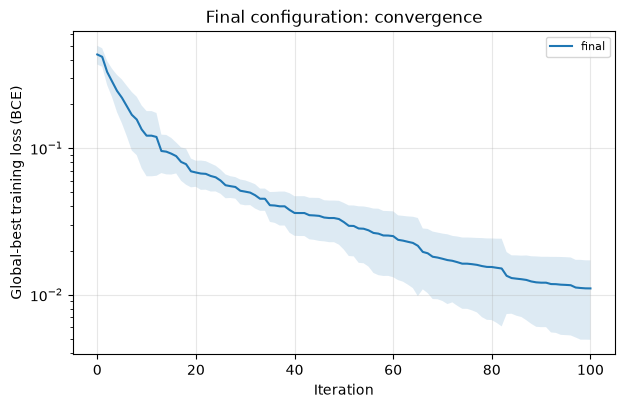

In [15]:
FINAL_CONFIG = dict(DEFAULT_CONFIG)      # <- edit with your chosen hyperparameters
final = run_experiment({"final": FINAL_CONFIG}, range(max(N_SEEDS, 10)), data, mode="test")
f = to_frame(final)
display(f[["train_loss", "eval_accuracy", "eval_precision", "eval_recall", "eval_f1"]]
        .agg(["mean", "std", "min", "max"]).T)
plot_convergence(histories_by_label(final), "Final configuration: convergence")
plt.show()

In [16]:
# Persist everything for the report
for name, res in RESULTS.items():
    to_frame(res).to_csv(f"results/{name}.csv", index=False)
to_frame(final).to_csv("results/final_test.csv", index=False)
json.dump({"final_config": FINAL_CONFIG, "n_seeds": N_SEEDS}, open("results/run_info.json", "w"), indent=2)
print("saved:", sorted(os.listdir("results")))

saved: ['README.md', 'final_test.csv', 'informants.csv', 'mlp_activation.csv', 'mlp_depth.csv', 'mlp_width.csv', 'pso_alpha.csv', 'pso_beta.csv', 'pso_delta.csv', 'pso_epsilon.csv', 'pso_gamma.csv', 'pso_iterations.csv', 'pso_particles.csv', 'run_info.json']
